### Prepare the PCA dataset

Prepare the flow measurements for PCA and keep their labels and timestamps for Section 2 of the assignment.


In [1]:
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

from src.preprocessing import DropAllZeroColumns, SpearmanFilter

In [2]:
df = pd.read_csv("dataset.csv")
df.columns = df.columns.str.strip()
flows = df.set_index("Unnamed: 0").drop(
    columns=[
        "Flow ID",
        "Source IP",
        "Source Port",
        "Destination IP",
        "Destination Port",
    ]
)

C:\Users\franc\AppData\Local\Temp\ipykernel_23824\108652544.py:1: DtypeWarning: Columns (85: SimillarHTTP) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("dataset.csv")


### Choose the PCA inputs

The original row ID keeps each flow aligned with its label and timestamp. `Flow ID` duplicates information in other columns. The prepared dataset also omits the source and destination IP addresses and ports.

PCA uses measurements and counts. `Inbound` and protocol indicators such as `Protocol_UDP` represent categories and stay with the metadata for inspection.


In [3]:
# Protocol numbers from the IANA registry.
# https://www.iana.org/assignments/protocol-numbers/protocol-numbers.xhtml
protocol_names = {0: "HOPOPT", 6: "TCP", 17: "UDP"}
flows["Protocol"] = (
    flows["Protocol"]
    .map(protocol_names)
    .fillna("Unknown_" + flows["Protocol"].astype(str))
)
flows = pd.get_dummies(flows, columns=["Protocol"], dtype=int)

categorical_columns = {"label", "Inbound"}
measurement_columns = [
    column
    for column in flows.select_dtypes(include="number").columns
    if column not in categorical_columns and not column.startswith("Protocol_")
]
X = flows[measurement_columns]
metadata = flows.drop(columns=measurement_columns)
y = metadata["label"].copy()

### Define the preprocessing pipeline

1. Drop measurements that are zero in every row used to fit the pipeline.
2. Scan the remaining measurements in column order. Drop a measurement if its absolute Spearman correlation with any retained measurement exceeds 0.9. For example, if two columns have a correlation of -0.95, keep the first.
3. Standardize the retained measurements so their units do not dominate PCA.
4. Keep enough principal components to explain at least 99% of the variance in the standardized measurements.
5. Name the component columns `PC1`, `PC2`, and so on. Pandas output carries the original row IDs through scaling and PCA.


In [4]:
def name_components(scores):
    names = [f"PC{i}" for i in range(1, scores.shape[1] + 1)]
    return scores.set_axis(names, axis="columns")


preprocess = Pipeline(
    [
        ("drop_all_zero", DropAllZeroColumns()),
        ("spearman", SpearmanFilter(threshold=0.9)),
        ("scale", StandardScaler().set_output(transform="pandas")),
        (
            "pca",
            PCA(n_components=0.99, svd_solver="full").set_output(transform="pandas"),
        ),
        ("name_components", FunctionTransformer(name_components)),
    ]
)

### Inspect the exploratory fit

Fit on all flows to inspect the feature removals and retained variance. `X_reduced` contains the components. `df_pca` joins them to the label and other metadata by row ID for analysis.


In [5]:
X_reduced = preprocess.fit_transform(X)
df_pca = pd.concat([X_reduced, metadata], axis=1)

In [6]:
columns_to_drop = preprocess.named_steps["drop_all_zero"].dropped_columns_
correlation_removals = preprocess.named_steps["spearman"].removals_
pca = preprocess.named_steps["pca"]
variance_retained = pca.explained_variance_ratio_.sum()

print(f"All-zero columns removed: {', '.join(columns_to_drop)}")
print(f"{pca.n_components_} components retain {variance_retained:.2%} of variance.")
correlation_removals

All-zero columns removed: Bwd PSH Flags, Fwd URG Flags, Bwd URG Flags, FIN Flag Count, PSH Flag Count, ECE Flag Count, Fwd Avg Bytes/Bulk, Fwd Avg Packets/Bulk, Fwd Avg Bulk Rate, Bwd Avg Bytes/Bulk, Bwd Avg Packets/Bulk, Bwd Avg Bulk Rate
20 components retain 99.12% of variance.


,Removed feature,Retained feature,Absolute Spearman correlation
0,Fwd Packet Length Max,Total Length of Fwd Packets,0.904084
1,Fwd Packet Length Mean,Fwd Packet Length Min,0.987166
2,Bwd Packet Length Max,Total Length of Bwd Packets,0.999984
3,Bwd Packet Length Mean,Total Length of Bwd Packets,0.999872
4,Flow Bytes/s,Fwd Packet Length Min,0.902712
5,Flow Packets/s,Flow Duration,0.996758
6,Flow IAT Mean,Flow Duration,0.995619
7,Flow IAT Max,Flow Duration,0.998428
8,Fwd IAT Mean,Fwd IAT Total,0.998426
9,Fwd IAT Std,Total Fwd Packets,0.922406


### Starting Section 2

Split the original measurements in `X` with the aligned labels in `y`. Use the timestamps in `metadata` to order the flows within each label for the temporal split.

For each split, fit a fresh copy of the pipeline on the training measurements and transform the test measurements with that fitted copy. This keeps test flows from influencing which columns we retain, how we scale them, or how PCA combines them.


In [7]:
print(X_reduced.columns)
X_nopca = preprocess[:-2].fit_transform(X)
print(X_nopca.shape)

Index(['PC1', 'PC2', 'PC3', 'PC4', 'PC5', 'PC6', 'PC7', 'PC8', 'PC9', 'PC10',
       'PC11', 'PC12', 'PC13', 'PC14', 'PC15', 'PC16', 'PC17', 'PC18', 'PC19',
       'PC20'],
      dtype='str')
(64239, 27)


# Training: Preparation of validation

Choose the training set and the test set and cross-validation object

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.model_selection import cross_val_score, cross_validate, train_test_split, StratifiedKFold

random_state = 42
k = 3

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=random_state, stratify=y)


## Stratified K fold validation

In [ ]:

skf = StratifiedKFold(n_splits=k, shuffle=True, random_state = random_state)

# Training pipeline: random forest

In [18]:
from src.modelclass import ModelClass


training = Pipeline(
    [
        ("preprocess", preprocess),
        ("classifier", RandomForestClassifier(random_state=random_state,n_jobs=4)),
    ]
)

rf_model = ModelClass(
    model=training,
    X=X,
    y=y,
)

## Hyperparameters tuning


In [19]:

### Hyperparameters for tuning
param_distributions = {
    "classifier__n_estimators": [100, 200, 300],
    "classifier__max_depth": [8, 12, 16, 20, None],
    "classifier__min_samples_leaf": [1, 2, 5, 10],
    "classifier__max_features": ["sqrt", "log2"],
    "classifier__class_weight": [None, "balanced"]
}

best_estimator, best_params, best_score = rf_model.hyperparameter_tuning(param_distributions)
print(f"Best estimator: {best_estimator}")
print(f"Best parameters: {best_params}")
print(f"Best score: {best_score}")

Best estimator: Pipeline(steps=[('preprocess',
                 Pipeline(steps=[('drop_all_zero', DropAllZeroColumns()),
                                 ('spearman', SpearmanFilter()),
                                 ('scale', StandardScaler()),
                                 ('pca',
                                  PCA(n_components=0.99, svd_solver='full')),
                                 ('name_components',
                                  FunctionTransformer(func=<function name_components at 0x000001FB2C43C880>))])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', max_depth=16,
                                        min_samples_leaf=2, n_estimators=200,
                                        n_jobs=4, random_state=42))])
Best parameters: {'classifier__n_estimators': 200, 'classifier__min_samples_leaf': 2, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 16, 'classifier__class_weight': 'balanced'}
Best score: 0.731

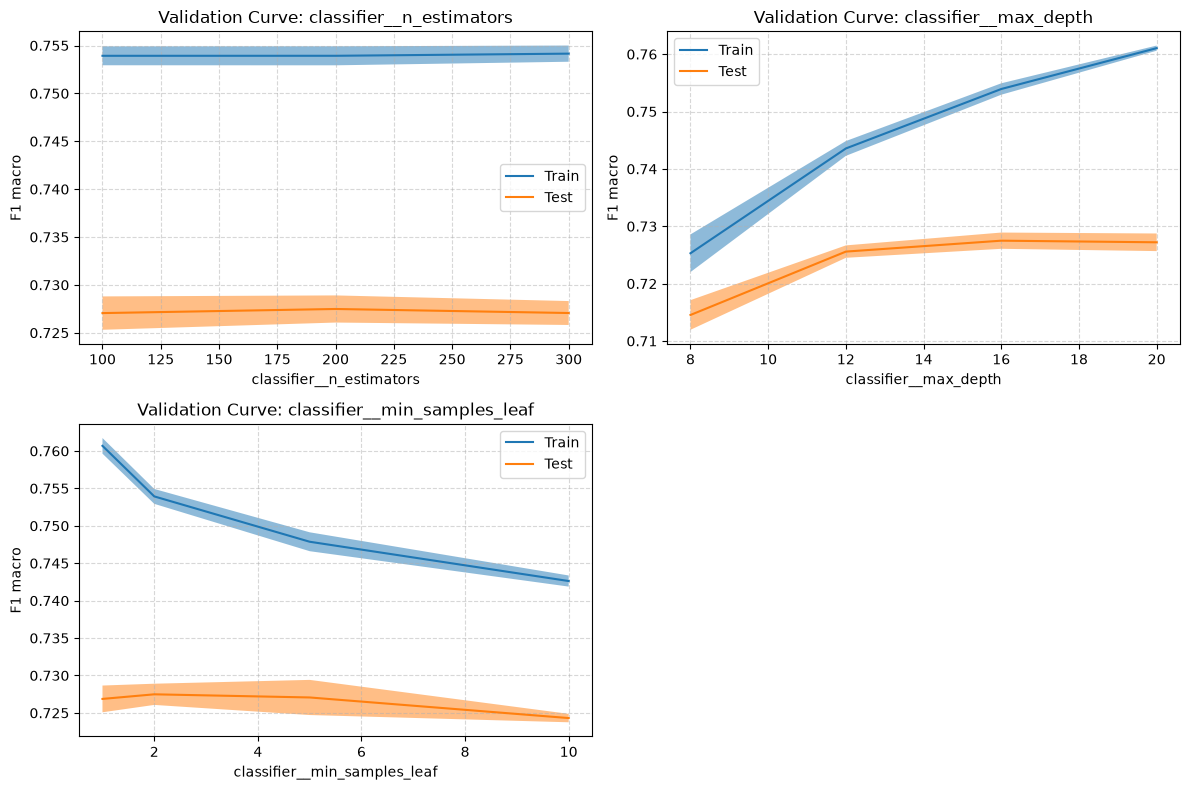

In [20]:
rf_model.showvalidationcurves()

## Prediction

In [21]:
print(rf_model.evaluate_model())

              precision    recall  f1-score   support

      benign       0.99      1.00      0.99      1132
    ddos_dns       0.98      0.84      0.90      1074
   ddos_ldap       0.50      0.67      0.58      1186
  ddos_mssql       0.48      0.11      0.18      1182
ddos_netbios       0.97      0.95      0.96      1166
    ddos_ntp       0.87      0.94      0.90       197
   ddos_snmp       1.00      1.00      1.00      1197
   ddos_ssdp       0.61      0.95      0.74      1194
    ddos_syn       0.98      0.44      0.61      1096
   ddos_tftp       0.63      0.99      0.77      1052
    ddos_udp       0.54      0.66      0.59      1175
ddos_udp_lag       0.57      0.44      0.50      1197

    accuracy                           0.73     12848
   macro avg       0.76      0.75      0.73     12848
weighted avg       0.75      0.73      0.71     12848

